In [20]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense, Dropout,
    GlobalAveragePooling2D, BatchNormalization
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import load_model


from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split


import shutil
from pathlib import Path
import pandas as pd
import random

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("✅ TensorFlow:", tf.__version__)
print("✅ GPU:", tf.config.list_physical_devices('GPU'))

✅ TensorFlow: 2.20.0
✅ GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# STEP 3: Dataset Organization — Train / Validation / Test Split
# ============================================================

SOURCE_DIR = "/content/drive/MyDrive/project/archive/train"
BASE_DIR = "/content/drive/MyDrive/project/dataset"

TRAIN_DIR = os.path.join(BASE_DIR, "train_split")
VAL_DIR   = os.path.join(BASE_DIR, "validation")
TEST_DIR  = os.path.join(BASE_DIR, "test")

# --- Class names (must match folder names exactly) ---
classes = ['yawn', 'no_yawn', 'Open', 'Closed']

# --- Create folder structure ---
for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    os.makedirs(folder, exist_ok=True)
    for cls in classes:
        os.makedirs(os.path.join(folder, cls), exist_ok=True)

print("✅ Folder structure created successfully.\n")

# --- Verify source folders exist before proceeding ---
for cls in classes:
    path = os.path.join(SOURCE_DIR, cls)
    if not os.path.isdir(path):
        print(f"WARNING: Source folder not found → {path}")
    else:
        print(f"✔  Found: {path}  ({len(os.listdir(path))} images)")

print()

# --- Split Ratios ---
random.seed(42)

train_ratio = 0.80
val_ratio   = 0.10
test_ratio  = 0.10

# --- Perform the split ---
for cls in classes:
    source_path = os.path.join(SOURCE_DIR, cls)

    # Filter only image files (skip hidden/system files)
    images = [f for f in os.listdir(source_path)
              if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp'))]

    random.shuffle(images)

    total_images = len(images)

    train_end = int(train_ratio * total_images)
    val_end   = train_end + int(val_ratio * total_images)

    train_images = images[:train_end]
    val_images   = images[train_end:val_end]
    test_images  = images[val_end:]

    # Copy Training Images
    for img in train_images:
        shutil.copy(
            os.path.join(source_path, img),
            os.path.join(TRAIN_DIR, cls, img)
        )

    # Copy Validation Images
    for img in val_images:
        shutil.copy(
            os.path.join(source_path, img),
            os.path.join(VAL_DIR, cls, img)
        )

    # Copy Test Images
    for img in test_images:
        shutil.copy(
            os.path.join(source_path, img),
            os.path.join(TEST_DIR, cls, img)
        )

    print(f"  {cls:10s} → Train: {len(train_images):4d} | Val: {len(val_images):4d} | Test: {len(test_images):4d}")

print("\n✅ Dataset successfully split into Train, Validation, and Test sets.\n")


# --- Verification: Count images in each split ---
def count_images(folder, classes):
    """Print image counts per class inside a folder."""
    print(f"\n{'='*35}")
    print(f"  {os.path.basename(folder).upper()}")
    print(f"{'='*35}")

    total = 0
    for cls in classes:
        cls_path = os.path.join(folder, cls)
        count = len(os.listdir(cls_path))
        total += count
        print(f"  {cls:10s} : {count}")

    print(f"  {'─'*25}")
    print(f"  {'TOTAL':10s} : {total}")
    return total


train_total = count_images(TRAIN_DIR, classes)
val_total   = count_images(VAL_DIR, classes)
test_total  = count_images(TEST_DIR, classes)

grand_total = train_total + val_total + test_total
print(f"\n{'='*35}")
print(f"  GRAND TOTAL : {grand_total}")
print(f"{'='*35}")

In [3]:
#============================================================
# Copying Split data to drive to load faster
# ============================================================
if os.path.exists("/content/dataset"):
    shutil.rmtree("/content/dataset")

shutil.copytree(
    "/content/drive/MyDrive/project/dataset",
    "/content/dataset"
)

print("✅ Dataset copied successfully!")

✅ Dataset copied successfully!


In [6]:
# ============================================================
# STEP 4 : DATA PREPROCESSING & DATA AUGMENTATION
# ============================================================


# Dataset Paths
TRAIN_DIR = "/content/dataset/dataset/train_split"
VAL_DIR   = "/content/dataset/dataset/validation"
TEST_DIR  = "/content/dataset/dataset/test"

# Image Parameters
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42


def create_generators(
    model_type="cnn",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED
):
    """
    Create train, validation and test generators.

    Parameters
    ----------
    model_type : str
        "cnn" or "mobilenet"

    Returns
    -------
    train_generator
    validation_generator
    test_generator
    """

    if model_type.lower() == "cnn":

        train_datagen = ImageDataGenerator(

            rescale=1./255,

            rotation_range=10,

            zoom_range=0.10,

            brightness_range=(0.9,1.1),

            horizontal_flip=True,

            fill_mode="nearest"

        )

        val_test_datagen = ImageDataGenerator(
            rescale=1./255
        )

    elif model_type.lower() == "mobilenet":

        train_datagen = ImageDataGenerator(

            preprocessing_function=preprocess_input,

            rotation_range=20,

            zoom_range=0.20,

            brightness_range=(0.8,1.2),

            horizontal_flip=True,

            fill_mode="nearest"

        )

        val_test_datagen = ImageDataGenerator(
            preprocessing_function=preprocess_input
        )

    else:

        raise ValueError(
            "model_type must be either 'cnn' or 'mobilenet'"
        )

    train_generator = train_datagen.flow_from_directory(

        TRAIN_DIR,

        target_size=image_size,

        batch_size=batch_size,

        class_mode="categorical",

        shuffle=True,

        seed=seed

    )

    validation_generator = val_test_datagen.flow_from_directory(

        VAL_DIR,

        target_size=image_size,

        batch_size=batch_size,

        class_mode="categorical",

        shuffle=False

    )

    test_generator = val_test_datagen.flow_from_directory(

        TEST_DIR,

        target_size=image_size,

        batch_size=batch_size,

        class_mode="categorical",

        shuffle=False

    )

    return train_generator, validation_generator, test_generator

In [7]:
# ============================================================
# Custom CNN Generators
# ============================================================

cnn_train_generator,cnn_validation_generator,cnn_test_generator = create_generators(model_type="cnn")

# ============================================================
# MobileNetV2 Generators
# ============================================================

mobilenet_train_generator, mobilenet_validation_generator, mobilenet_test_generator = create_generators (model_type="mobilenet")

Found 2329 images belonging to 4 classes.
Found 288 images belonging to 4 classes.
Found 294 images belonging to 4 classes.
Found 2329 images belonging to 4 classes.
Found 288 images belonging to 4 classes.
Found 294 images belonging to 4 classes.


In [8]:
# Verification Function

def verify_generator(generator, model_name):
    """
    Verify image preprocessing for a generator.
    """

    images, labels = next(generator)

    print("="*60)
    print(model_name)
    print("="*60)

    print(f"Images Shape : {images.shape}")
    print(f"Labels Shape : {labels.shape}")
    print(f"Pixel Min    : {images.min():.4f}")
    print(f"Pixel Max    : {images.max():.4f}")

    return images, labels

In [9]:
# 4.3: Verify generators

cnn_batch, cnn_labels = verify_generator(
    cnn_train_generator,
    "Custom CNN"
)

mob_batch, mob_labels = verify_generator(
    mobilenet_train_generator,
    "MobileNetV2"
)

Custom CNN
Images Shape : (32, 224, 224, 3)
Labels Shape : (32, 4)
Pixel Min    : 0.0000
Pixel Max    : 1.0000
MobileNetV2
Images Shape : (32, 224, 224, 3)
Labels Shape : (32, 4)
Pixel Min    : -1.0000
Pixel Max    : 1.0000


In [10]:
# ============================================================
# # 4.4: Visualize augmented samples
# Show & Save Augmented Samples
# ============================================================

def show_and_save_augmented_samples(
    generator,
    model_name,
    output_dir,
    num_images=8
):
    """
    Display and save augmented training images.

    Parameters
    ----------
    generator : DirectoryIterator
        Training data generator.

    model_name : str
        Model name (Custom CNN / MobileNetV2).

    output_dir : str
        Folder to save the image.

    num_images : int
        Number of images to display.
    """

    images, labels = next(generator)

    class_names = list(generator.class_indices.keys())

    rows = 2
    cols = 4

    fig, axes = plt.subplots(rows, cols, figsize=(16,8))

    fig.suptitle(
        f"{model_name} - Augmented Training Samples",
        fontsize=16,
        fontweight="bold"
    )

    for i, ax in enumerate(axes.flat):

        if i >= num_images:
            ax.axis("off")
            continue

        img = images[i]

        # MobileNet images are [-1,1]
        if img.min() < 0:
            img = (img + 1) / 2

        label = class_names[np.argmax(labels[i])]

        ax.imshow(np.clip(img,0,1))
        ax.set_title(label)
        ax.axis("off")

    plt.tight_layout()

    filename = os.path.join(
        output_dir,
        f"{model_name.lower().replace(' ','_')}_augmented_samples.png"
    )

    plt.savefig(
        filename,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    print(f"✅ Saved: {filename}")

Output directory: /content/drive/MyDrive/project/outputs/step4_preprocessing


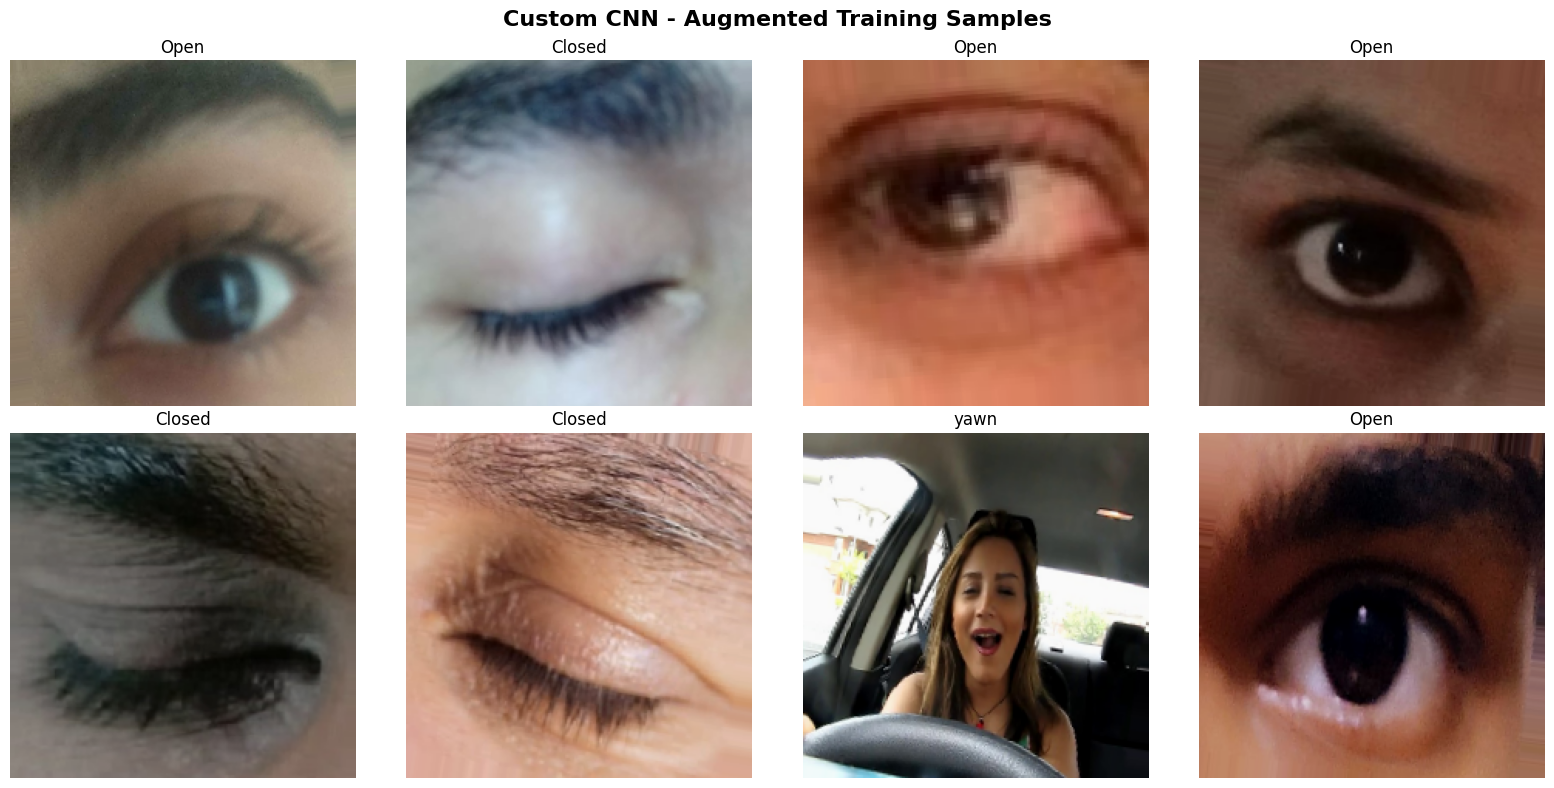

✅ Saved: /content/drive/MyDrive/project/outputs/step4_preprocessing/custom_cnn_augmented_samples.png


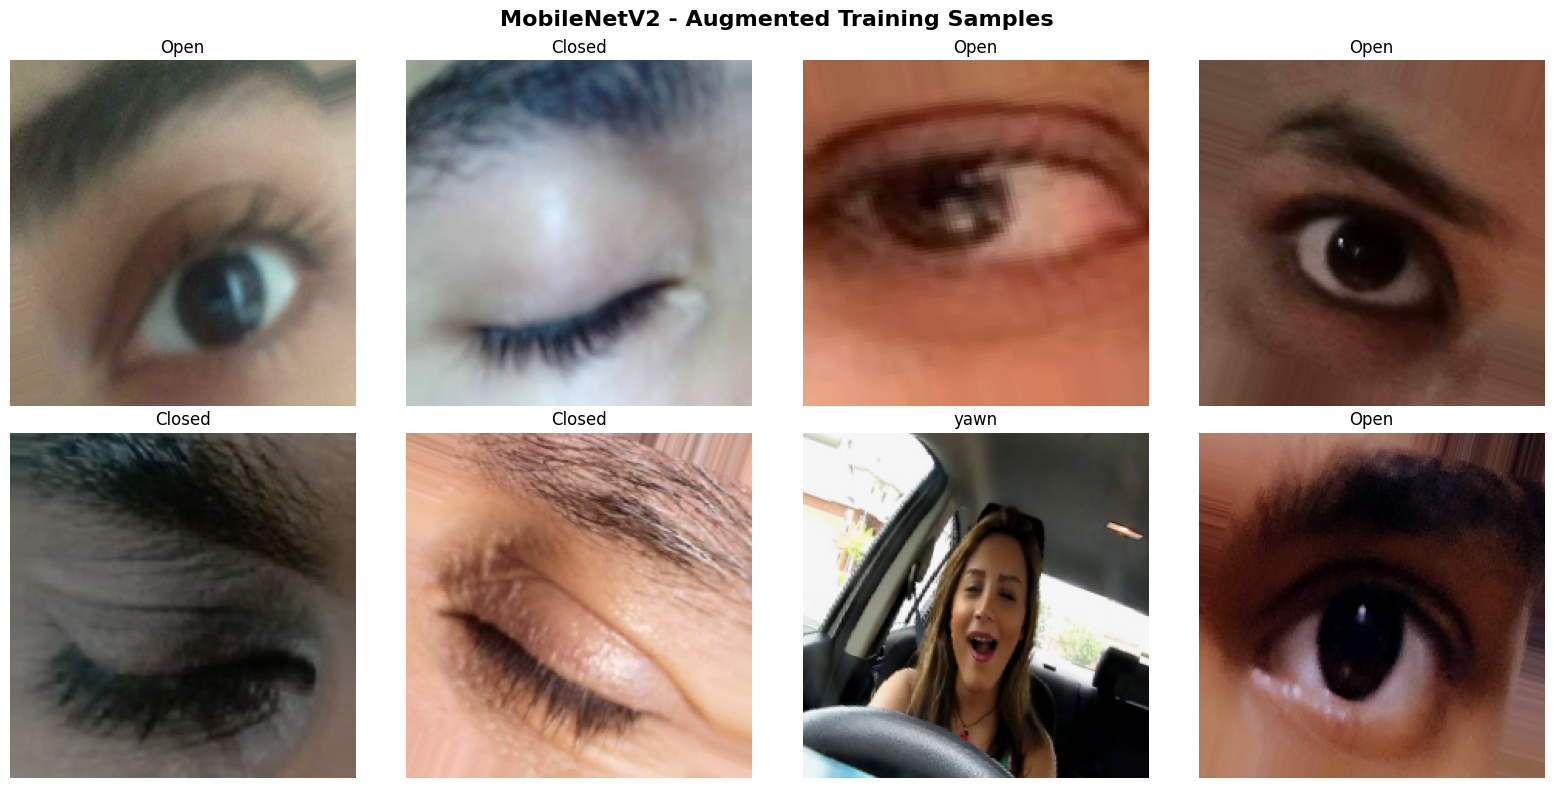

✅ Saved: /content/drive/MyDrive/project/outputs/step4_preprocessing/mobilenetv2_augmented_samples.png


In [11]:
OUTPUT_DIR = "/content/drive/MyDrive/project/outputs/step4_preprocessing"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Output directory: {OUTPUT_DIR}")

show_and_save_augmented_samples(
    cnn_train_generator,
    "Custom CNN",
    OUTPUT_DIR
)

show_and_save_augmented_samples(
    mobilenet_train_generator,
    "MobileNetV2",
    OUTPUT_DIR
)



In [12]:
# ============================================================
# Save Preprocessing Summary
# ============================================================

import os


def save_preprocessing_summary(
    cnn_train_generator,
    mobilenet_train_generator,
    cnn_batch,
    mobile_batch,
    output_dir,
    image_size=(224,224),
    batch_size=32
):
    """
    Generate and save preprocessing summary.
    """

    summary = f"""
============================================================
PREPROCESSING SUMMARY
============================================================

Image Size      : {image_size}

Batch Size      : {batch_size}

------------------------------------------------------------
Custom CNN
------------------------------------------------------------

Training
- Rescale (0-1)
- Rotation
- Zoom
- Brightness
- Horizontal Flip

Validation/Test
- Rescale only

Pixel Range

Minimum : {cnn_batch.min():.4f}

Maximum : {cnn_batch.max():.4f}

------------------------------------------------------------
MobileNetV2
------------------------------------------------------------

Training
- preprocess_input()
- Rotation
- Zoom
- Brightness
- Horizontal Flip

Validation/Test
- preprocess_input()

Pixel Range

Minimum : {mobile_batch.min():.4f}

Maximum : {mobile_batch.max():.4f}

------------------------------------------------------------
Dataset Information
------------------------------------------------------------

Training Images   : {cnn_train_generator.samples}

Validation Images : {cnn_train_generator.samples}

Testing Images    : {cnn_train_generator.samples}

Class Labels

{cnn_train_generator.class_indices}

============================================================
"""

    print(summary)

    filename = os.path.join(
        output_dir,
        "preprocessing_summary.txt"
    )

    with open(filename,"w") as f:
        f.write(summary)

    print(f"✅ Saved: {filename}")

In [13]:
# 4.5: Save preprocessing summary
save_preprocessing_summary(
    cnn_train_generator,
    mobilenet_train_generator,
    cnn_batch,
    mob_batch,
    OUTPUT_DIR
)


PREPROCESSING SUMMARY

Image Size      : (224, 224)

Batch Size      : 32

------------------------------------------------------------
Custom CNN
------------------------------------------------------------

Training
- Rescale (0-1)
- Rotation
- Zoom
- Brightness
- Horizontal Flip

Validation/Test
- Rescale only

Pixel Range

Minimum : 0.0000

Maximum : 1.0000

------------------------------------------------------------
MobileNetV2
------------------------------------------------------------

Training
- preprocess_input()
- Rotation
- Zoom
- Brightness
- Horizontal Flip

Validation/Test
- preprocess_input()

Pixel Range

Minimum : -1.0000

Maximum : 1.0000

------------------------------------------------------------
Dataset Information
------------------------------------------------------------

Training Images   : 2329

Validation Images : 2329

Testing Images    : 2329

Class Labels

{'Closed': 0, 'Open': 1, 'no_yawn': 2, 'yawn': 3}


✅ Saved: /content/drive/MyDrive/project/outp

In [14]:
# ============================================================
# STEP 5 & 6 & 7: Model Buid, Development & Training
# ============================================================

# ============================================================
# STEP 5.1: Custom CNN Model Buid & Development
# ============================================================
def build_custom_cnn():

    model = Sequential([

        #####################################################
        Input(shape=(224,224,3)),

        #####################################################

        Conv2D(
            32,
            (3,3),
            activation='relu',
            padding='same',
            kernel_initializer='he_normal'
        ),

        BatchNormalization(),

        MaxPooling2D(pool_size=(2,2)),

        #####################################################

        Conv2D(
            64,
            (3,3),
            activation='relu',
            padding='same',
            kernel_initializer='he_normal'
        ),

        BatchNormalization(),

        MaxPooling2D(pool_size=(2,2)),

        #####################################################

        Conv2D(
            128,
            (3,3),
            activation='relu',
            padding='same',
            kernel_initializer='he_normal'
        ),

        BatchNormalization(),

        MaxPooling2D(pool_size=(2,2)),

        #####################################################

        Conv2D(
            256,
            (3,3),
            activation='relu',
            padding='same',
            kernel_initializer='he_normal'
        ),

        BatchNormalization(),

        MaxPooling2D(pool_size=(2,2)),

        #####################################################

        GlobalAveragePooling2D(),

        #####################################################

        Dense(
            256,
            activation='relu'
        ),

        Dropout(0.30),

        Dense(
            128,
            activation='relu'
        ),

        Dropout(0.20),

        #####################################################

        Dense(
            4,
            activation='softmax'
        )

    ])

    return model


custom_cnn = build_custom_cnn()
custom_cnn.summary()

custom_cnn = build_custom_cnn()

custom_cnn.compile(

    optimizer=Adam(learning_rate=1e-4),

    loss="categorical_crossentropy",

    metrics=["accuracy"]

)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,540 (1.87 MB)

 Trainable params: 488,580 (1.86 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
# print(cnn_train_generator.class_indices)
# print(cnn_train_generator.num_classes)

In [21]:
# ============================================================
# 5.2 Mobilenetv2 Model Build
# ============================================================

def build_mobilenet():

    base_model = MobileNetV2(

        weights='imagenet',

        include_top=False,

        input_shape=(224,224,3)

    )

    ################################################

    base_model.trainable = False

    ################################################

    x = base_model.output

    x = GlobalAveragePooling2D()(x)

    x = Dense(
        256,
        activation='relu'
    )(x)

    x = Dropout(0.5)(x)

    x = Dense(
        128,
        activation='relu'
    )(x)

    x = Dropout(0.3)(x)

    ################################################

    outputs = Dense(
        4,
        activation='softmax'
    )(x)

    ################################################

    model = Model(

        inputs=base_model.input,

        outputs=outputs

    )

    return model


mobilenet_model = build_mobilenet()

mobilenet_model.summary()

mobilenet_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)



Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_3[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,619,332 (9.99 MB)

 Trainable params: 361,348 (1.38 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
mobilenet_model.output_shape

(None, 4)

In [17]:
# ============================================================
# Step 7: Model Training
# ============================================================

def train_model(
    model,
    train_generator,
    validation_generator,
    checkpoint_path,
    epochs=20,
    learning_rate=None
):
    """
    Train any Keras model using common callbacks.

    Parameters
    ----------
    model : keras.Model
        Compiled model

    train_generator : DirectoryIterator

    validation_generator : DirectoryIterator

    checkpoint_path : str
        Path to save the best model

    epochs : int
        Number of training epochs

    learning_rate : float (optional)
        If provided, updates optimizer learning rate.

    Returns
    -------
    history
    """

    # Optional learning rate update
    if learning_rate is not None:
        model.optimizer.learning_rate.assign(learning_rate)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        verbose=1
    )

    checkpoint = ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )

    history = model.fit(

        train_generator,

        validation_data=validation_generator,

        epochs=epochs,

        callbacks=[
            early_stop,
            reduce_lr,
            checkpoint
        ]

    )

    return history

In [18]:
# ============================================================
# 7.2 Training custom CNN
# ============================================================

cnn_history = train_model(

    model=custom_cnn,

    train_generator=cnn_train_generator,

    validation_generator=cnn_validation_generator,

    checkpoint_path="best_custom_cnn.keras",

    epochs=20

)

Epoch 1/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 671ms/step - accuracy: 0.4595 - loss: 1.1000
Epoch 1: val_accuracy improved from None to 0.25000, saving model to best_custom_cnn.keras

Epoch 1: finished saving model to best_custom_cnn.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 67s 724ms/step - accuracy: 0.5324 - loss: 0.9102 - val_accuracy: 0.2500 - val_loss: 1.5180 - learning_rate: 1.0000e-04
Epoch 2/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 522ms/step - accuracy: 0.5989 - loss: 0.7503
Epoch 2: val_accuracy did not improve from 0.25000
73/73 ━━━━━━━━━━━━━━━━━━━━ 39s 533ms/step - accuracy: 0.5878 - loss: 0.7491 - val_accuracy: 0.2500 - val_loss: 2.2347 - learning_rate: 1.0000e-04
Epoch 3/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 546ms/step - accuracy: 0.6184 - loss: 0.6957
Epoch 3: val_accuracy did not improve from 0.25000
73/73 ━━━━━━━━━━━━━━━━━━━━ 41s 557ms/step - accuracy: 0.6071 - loss: 0.6964 - val_accuracy: 0.2500 - val_loss: 2.3969 - learning_rate: 1.0000e-04
Epoch 4/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 561ms/step - 

In [29]:
cnn_history_df = pd.DataFrame(cnn_history.history)

os.makedirs("output", exist_ok=True)

cnn_history_df.to_csv("output/cnn_training_history.csv", index=False)

shutil.copy(
    "output/cnn_training_history.csv",
    "/content/drive/MyDrive/project/cnn_training_history.csv"
)


'/content/drive/MyDrive/project/cnn_training_history.csv'

In [23]:
# ============================================================
# 7.2 Training MobileNetV2
# ============================================================

mobilenet_history = train_model(

    model=mobilenet_model,

    train_generator=mobilenet_train_generator,

    validation_generator=mobilenet_validation_generator,

    checkpoint_path="best_mobilenetv2.keras",

    epochs=20

)

Epoch 1/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 720ms/step - accuracy: 0.4281 - loss: 1.3293
Epoch 1: val_accuracy improved from None to 0.82292, saving model to best_mobilenetv2.keras

Epoch 1: finished saving model to best_mobilenetv2.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 89s 835ms/step - accuracy: 0.5513 - loss: 1.0231 - val_accuracy: 0.8229 - val_loss: 0.4544 - learning_rate: 1.0000e-04
Epoch 2/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 525ms/step - accuracy: 0.7288 - loss: 0.5979
Epoch 2: val_accuracy improved from 0.82292 to 0.84375, saving model to best_mobilenetv2.keras

Epoch 2: finished saving model to best_mobilenetv2.keras
73/73 ━━━━━━━━━━━━━━━━━━━━ 40s 555ms/step - accuracy: 0.7398 - loss: 0.5570 - val_accuracy: 0.8438 - val_loss: 0.3375 - learning_rate: 1.0000e-04
Epoch 3/20
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 507ms/step - accuracy: 0.7696 - loss: 0.4918
Epoch 3: val_accuracy did not improve from 0.84375
73/73 ━━━━━━━━━━━━━━━━━━━━ 39s 521ms/step - accuracy: 0.7793 - loss: 0.4616 - val_accuracy: 0.83

In [30]:
history_df = pd.DataFrame(mobilenet_history.history)

os.makedirs("output", exist_ok=True)

history_df.to_csv("output/mobilenet_training_history.csv", index=False)

shutil.copy(
    "output/mobilenet_training_history.csv",
    "/content/drive/MyDrive/project/mobilenet_training_history.csv"
)



'/content/drive/MyDrive/project/mobilenet_training_history.csv'

In [31]:
# ============================================================
# Copying the best trainied models to drive
# ============================================================

def load_best_model(model_path):
    """
    Load the best saved Keras model.

    Parameters
    ----------
    model_path : str
        Path to the saved .keras model

    Returns
    -------
    keras.Model
    """

    model = load_model(model_path)

    print("=" * 60)
    print(f"Loaded Model: {model_path}")
    print("=" * 60)

    return model

In [32]:
# ============================================================
# Loading the saved trainied models to drive
# ============================================================
custom_cnn = load_best_model("best_custom_cnn.keras")

mobilenet_model = load_best_model("best_mobilenetv2.keras")

Loaded Model: best_custom_cnn.keras
Loaded Model: best_mobilenetv2.keras


In [33]:
# ============================================================
# Copying the best trainied models to drive
# ============================================================

shutil.copy(
    "best_custom_cnn.keras",
    "/content/drive/MyDrive/project/best_custom_cnn.keras"
)

shutil.copy(
    "best_mobilenetv2.keras",
    "/content/drive/MyDrive/project/best_mobilenetv2.keras"
)

print("✅ Models saved to Google Drive.")

✅ Models saved to Google Drive.


In [34]:
# ============================================================
# Best Trained Model
# ============================================================
best_epoch = np.argmax(cnn_history.history["val_accuracy"])

print("="*60)
print("CUSTOM CNN")
print("="*60)
print(f"Best Epoch              : {best_epoch + 1}")
print(f"Validation Accuracy     : {cnn_history.history['val_accuracy'][best_epoch]*100:.2f}%")
print(f"Validation Loss         : {cnn_history.history['val_loss'][best_epoch]:.4f}")

print("="*60)

best_epoch = np.argmax(mobilenet_history.history["val_accuracy"])

print("="*60)
print("MOBILENETV2")
print("="*60)
print(f"Best Epoch              : {best_epoch + 1}")
print(f"Validation Accuracy     : {mobilenet_history.history['val_accuracy'][best_epoch]*100:.2f}%")
print(f"Validation Loss         : {mobilenet_history.history['val_loss'][best_epoch]:.4f}")

CUSTOM CNN
Best Epoch              : 17
Validation Accuracy     : 74.31%
Validation Loss         : 0.5290
MOBILENETV2
Best Epoch              : 17
Validation Accuracy     : 89.58%
Validation Loss         : 0.2508


In [35]:
# ============================================================
#Step 8: Model Evaluation
# ============================================================

def evaluate_model(model, test_generator, model_name):
    """
    Evaluate a trained classification model.

    Parameters
    ----------
    model : keras.Model
        Trained model.

    test_generator : DirectoryIterator
        Test data generator.

    model_name : str
        Name of the model.

    Returns
    -------
    metrics : dict
        Dictionary containing evaluation metrics.

    report_df : DataFrame
        Classification report.

    y_true : ndarray
        Ground truth labels.

    y_pred : ndarray
        Predicted labels.
    """

    # --------------------------------------------------------
    # Evaluate model
    # --------------------------------------------------------

    test_loss, test_accuracy = model.evaluate(
        test_generator,
        verbose=1
    )

    print("=" * 60)
    print(f"{model_name} Evaluation Results")
    print("=" * 60)
    print(f"Test Accuracy : {test_accuracy*100:.2f}%")
    print(f"Test Loss     : {test_loss:.4f}")

    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    test_generator.reset()

    pred_prob = model.predict(
        test_generator,
        verbose=1
    )

    y_pred = np.argmax(pred_prob, axis=1)
    y_true = test_generator.classes

    # --------------------------------------------------------
    # Confusion Matrix
    # --------------------------------------------------------

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8,6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=test_generator.class_indices.keys(),
        yticklabels=test_generator.class_indices.keys()
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"{model_name} - Confusion Matrix")

    plt.show()

    # --------------------------------------------------------
    # Classification Report
    # --------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        target_names=list(test_generator.class_indices.keys()),
        output_dict=True
    )

    report_df = pd.DataFrame(report).transpose()

    print(f"\n{model_name} Classification Report\n")
    display(report_df)

    metrics = {

        "Model": model_name,

        "Test Accuracy": round(test_accuracy * 100, 2),

        "Test Loss": round(test_loss, 4)

    }

    return metrics, report_df, y_true, y_pred

10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 327ms/step - accuracy: 0.6939 - loss: 0.5799
Custom CNN Evaluation Results
Test Accuracy : 69.39%
Test Loss     : 0.5799
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step


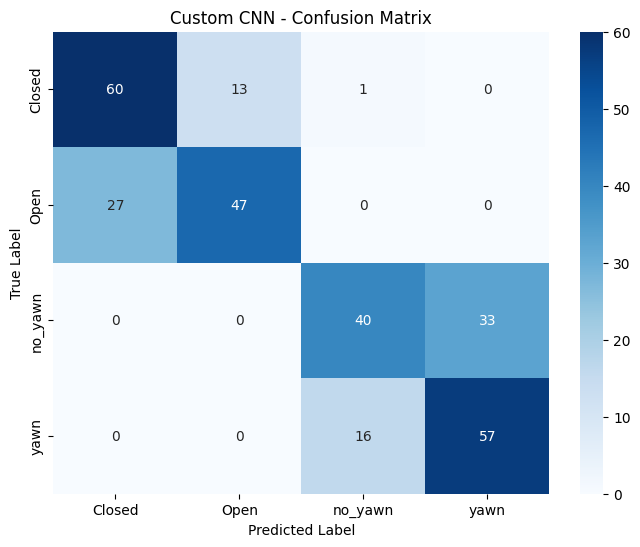


Custom CNN Classification Report



,precision,recall,f1-score,support
Closed,0.689655,0.810811,0.745342,74.000000
Open,0.783333,0.635135,0.701493,74.000000
no_yawn,0.701754,0.547945,0.615385,73.000000
yawn,0.633333,0.780822,0.699387,73.000000
accuracy,0.693878,0.693878,0.693878,0.693878
macro avg,0.702019,0.693678,0.690401,294.000000
weighted avg,0.702254,0.693878,0.690626,294.000000


10/10 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.8810 - loss: 0.2266
MobileNetV2 Evaluation Results
Test Accuracy : 88.10%
Test Loss     : 0.2266
10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 600ms/step


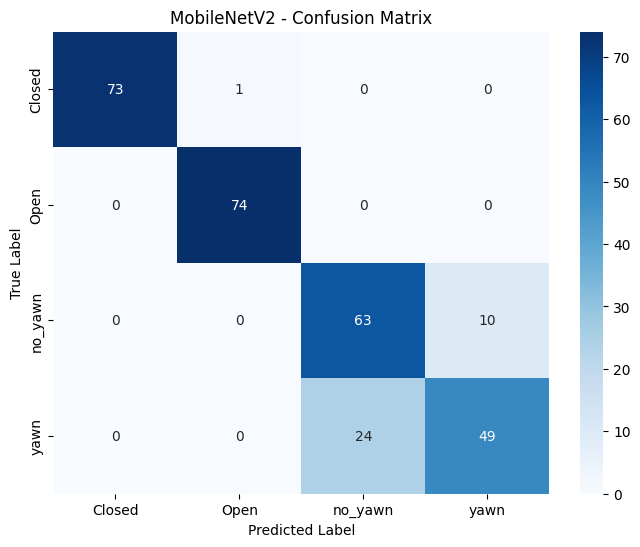


MobileNetV2 Classification Report



,precision,recall,f1-score,support
Closed,1.000000,0.986486,0.993197,74.000000
Open,0.986667,1.000000,0.993289,74.000000
no_yawn,0.724138,0.863014,0.787500,73.000000
yawn,0.830508,0.671233,0.742424,73.000000
accuracy,0.880952,0.880952,0.880952,0.880952
macro avg,0.885328,0.880183,0.879103,294.000000
weighted avg,0.886063,0.880952,0.879879,294.000000


In [36]:
# Evaluating Custom CNN

cnn_metrics, cnn_report, y_true_cnn, y_pred_cnn = evaluate_model(
    model=custom_cnn,
    test_generator=cnn_test_generator,
    model_name="Custom CNN"
)

# Evaluating Cmobilenet
mobile_metrics, mobile_report, y_true_mobile, y_pred_mobile = evaluate_model(
    model=mobilenet_model,
    test_generator=mobilenet_test_generator,
    model_name="MobileNetV2"
)

In [39]:
# To view the summary

print(cnn_metrics)
print(mobile_metrics)

{'Model': 'Custom CNN', 'Test Accuracy': 69.39, 'Test Loss': 0.5799}
{'Model': 'MobileNetV2', 'Test Accuracy': 88.1, 'Test Loss': 0.2266}


In [40]:
# ============================================================
# Step 9 : Decision Fusion Logic
# ============================================================

def decision_fusion(
    y_pred,
    test_generator,
    model_name,
    output_dir="outputs/step9_decision_fusion"
):
    """
    Maps the 4-class predictions into 3 fatigue stages.

    Parameters
    ----------
    y_pred : ndarray
        Predicted class indices.

    test_generator : DirectoryIterator
        Test generator used during evaluation.

    model_name : str
        Model name (Custom CNN / MobileNetV2).

    output_dir : str
        Folder to save CSV results.

    Returns
    -------
    results_df : DataFrame
        Prediction with fatigue stages.

    fatigue_predictions : list
        Numeric fatigue scores (0,1,2).
    """

    os.makedirs(output_dir, exist_ok=True)

    # --------------------------------------------------
    # Fatigue Mapping
    # --------------------------------------------------

    fatigue_mapping = {
        "Open": 0,
        "no_yawn": 0,
        "yawn": 1,
        "Closed": 2
    }

    fatigue_labels = {
        0: "Alert",
        1: "Mild Fatigue",
        2: "Severe Fatigue"
    }

    # --------------------------------------------------
    # Class Names
    # --------------------------------------------------

    class_names = list(test_generator.class_indices.keys())

    # --------------------------------------------------
    # Predicted Classes
    # --------------------------------------------------

    predicted_class_names = [
        class_names[i]
        for i in y_pred
    ]

    # --------------------------------------------------
    # Fatigue Scores
    # --------------------------------------------------

    fatigue_predictions = [
        fatigue_mapping[c]
        for c in predicted_class_names
    ]

    fatigue_stage_names = [
        fatigue_labels[s]
        for s in fatigue_predictions
    ]

    # --------------------------------------------------
    # Results DataFrame
    # --------------------------------------------------

    results_df = pd.DataFrame({

        "Predicted Class": predicted_class_names,

        "Fatigue Score": fatigue_predictions,

        "Fatigue Stage": fatigue_stage_names

    })

    # --------------------------------------------------
    # Summary
    # --------------------------------------------------

    summary_df = (
        results_df
        .value_counts()
        .reset_index(name="Count")
    )

    print("=" * 60)
    print(f"{model_name} - Decision Fusion Summary")
    print("=" * 60)

    display(summary_df)

    # --------------------------------------------------
    # Save CSV Files
    # --------------------------------------------------

    results_df.to_csv(
        os.path.join(
            output_dir,
            f"{model_name.lower().replace(' ','_')}_decision_fusion.csv"
        ),
        index=False
    )

    summary_df.to_csv(
        os.path.join(
            output_dir,
            f"{model_name.lower().replace(' ','_')}_decision_summary.csv"
        ),
        index=False
    )

    print("Decision Fusion Results Saved Successfully.\n")

    return results_df, fatigue_predictions

In [41]:
cnn_results, fatigue_predictions_cnn = decision_fusion(

    y_pred=y_pred_cnn,

    test_generator=cnn_test_generator,

    model_name="Custom CNN"

)

Custom CNN - Decision Fusion Summary


,Predicted Class,Fatigue Score,Fatigue Stage,Count
0,yawn,1,Mild Fatigue,90
1,Closed,2,Severe Fatigue,87
2,Open,0,Alert,60
3,no_yawn,0,Alert,57


Decision Fusion Results Saved Successfully.



In [42]:
mobile_results, fatigue_predictions_mobile = decision_fusion(

    y_pred=y_pred_mobile,

    test_generator=mobilenet_test_generator,

    model_name="MobileNetV2"

)

MobileNetV2 - Decision Fusion Summary


,Predicted Class,Fatigue Score,Fatigue Stage,Count
0,no_yawn,0,Alert,87
1,Open,0,Alert,75
2,Closed,2,Severe Fatigue,73
3,yawn,1,Mild Fatigue,59


Decision Fusion Results Saved Successfully.



In [45]:
import os

output_dir = "outputs/step9_decision_fusion"

print(os.listdir(output_dir))


['mobilenetv2_decision_summary.csv', 'custom_cnn_decision_summary.csv', 'custom_cnn_decision_fusion.csv', 'mobilenetv2_decision_fusion.csv']


In [46]:
# Copying files to drive

output_dir = "outputs/step9_decision_fusion"

drive_output = "/content/drive/MyDrive/project/outputs/step9_decision_fusion"

os.makedirs(drive_output, exist_ok=True)

files = [
    "custom_cnn_decision_fusion.csv",
    "custom_cnn_decision_summary.csv",
    "mobilenetv2_decision_fusion.csv",
    "mobilenetv2_decision_summary.csv"
]

for file in files:
    source = os.path.join(output_dir, file)
    if os.path.exists(source):
        shutil.copy(source, drive_output)
        print(f"✅ Copied {file}")
    else:
        print(f"❌ File not found: {source}")

print("Finished.")

✅ Copied custom_cnn_decision_fusion.csv
✅ Copied custom_cnn_decision_summary.csv
✅ Copied mobilenetv2_decision_fusion.csv
✅ Copied mobilenetv2_decision_summary.csv
Finished.


In [51]:
# ============================================================
# Step 10 : Driver Fatigue Progression Curve
# ============================================================


def fatigue_progression_curve(results_df,
                              model_name="Model",
                              frames_per_interval=10,
                              save_plot=True):

    np.random.seed(42)

    # -------------------------------------------------------
    # Split into fatigue stages
    # -------------------------------------------------------

    alert = results_df[results_df["Fatigue Stage"] == "Alert"]

    mild = results_df[results_df["Fatigue Stage"] == "Mild Fatigue"]

    severe = results_df[results_df["Fatigue Stage"] == "Severe Fatigue"]

    # -------------------------------------------------------
    # Safe sampling function
    # -------------------------------------------------------

    def sample_stage(df, n):

        replace = len(df) < n

        return df.sample(
            n=n,
            replace=replace,
            random_state=np.random.randint(10000)
        )

    # -------------------------------------------------------
    # Simulated Driving Session
    # -------------------------------------------------------

    # Total predictions
    N = len(results_df)

    # Actual counts
    alert_count = len(alert)
    mild_count = len(mild)
    severe_count = len(severe)

    # Simulated driving proportions
    early_alert = int(alert_count * 0.60)

    middle_alert = alert_count - early_alert

    early_mild = int(mild_count * 0.40)

    late_mild = mild_count - early_mild

    early_severe = int(severe_count * 0.30)

    late_severe = severe_count - early_severe



    simulated = pd.concat([

      sample_stage(alert, early_alert),

      sample_stage(mild, early_mild),

      sample_stage(alert, middle_alert),

      sample_stage(mild, late_mild),

      sample_stage(severe, early_severe),

      sample_stage(severe, late_severe)

], ignore_index=True)
    # -------------------------------------------------------
    # Convert Stage → Score
    # -------------------------------------------------------

    score_map = {

        "Alert":0,

        "Mild Fatigue":1,

        "Severe Fatigue":2

    }

    fatigue_scores = simulated["Fatigue Stage"].map(score_map).values

    # -------------------------------------------------------
    # Compute Progression
    # -------------------------------------------------------

    progression = []

    for i in range(0,len(fatigue_scores),frames_per_interval):

        progression.append(
            np.mean(
                fatigue_scores[i:i+frames_per_interval]
            )
        )

    # -------------------------------------------------------
    # Convert Average Score → Stage
    # -------------------------------------------------------

    progression_stage = []

    for score in progression:

        if score < 0.5:

            progression_stage.append("Alert")

        elif score < 1.5:

            progression_stage.append("Mild Fatigue")

        else:

            progression_stage.append("Severe Fatigue")

    # -------------------------------------------------------
    # Summary Table
    # -------------------------------------------------------

    summary = pd.DataFrame({

        "Time Interval":np.arange(1,len(progression)+1),

        "Fatigue Score":np.round(progression,2),

        "Stage":progression_stage

    })

    # -------------------------------------------------------
    # Plot
    # -------------------------------------------------------

    plt.figure(figsize=(12,6))

    plt.plot(

        progression,

        marker='o',

        linewidth=3

    )

    plt.yticks(

        [0,1,2],

        ["Alert","Mild Fatigue","Severe Fatigue"]

    )

    plt.xlabel("Driving Time Interval")

    plt.ylabel("Fatigue Level")

    plt.title(f"{model_name} Driver Fatigue Progression Curve")

    plt.grid(True)

    if save_plot:

        plt.savefig(

            f"{model_name}_Fatigue_Progression_Curve.png",

            dpi=300,

            bbox_inches="tight"

        )

    plt.show()

    return summary

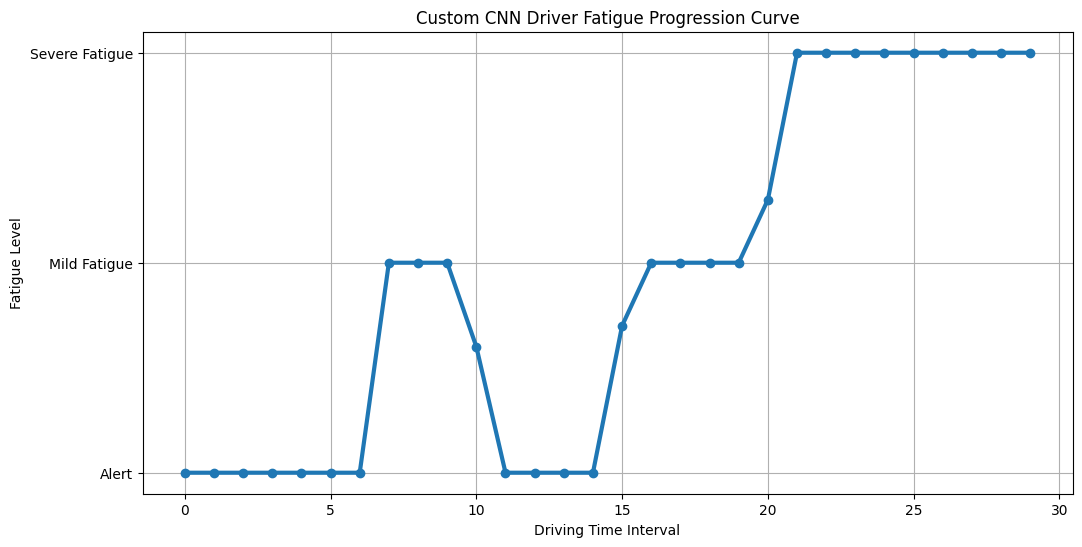

    Time Interval  Fatigue Score           Stage
0               1            0.0           Alert
1               2            0.0           Alert
2               3            0.0           Alert
3               4            0.0           Alert
4               5            0.0           Alert
5               6            0.0           Alert
6               7            0.0           Alert
7               8            1.0    Mild Fatigue
8               9            1.0    Mild Fatigue
9              10            1.0    Mild Fatigue
10             11            0.6    Mild Fatigue
11             12            0.0           Alert
12             13            0.0           Alert
13             14            0.0           Alert
14             15            0.0           Alert
15             16            0.7    Mild Fatigue
16             17            1.0    Mild Fatigue
17             18            1.0    Mild Fatigue
18             19            1.0    Mild Fatigue
19             20   

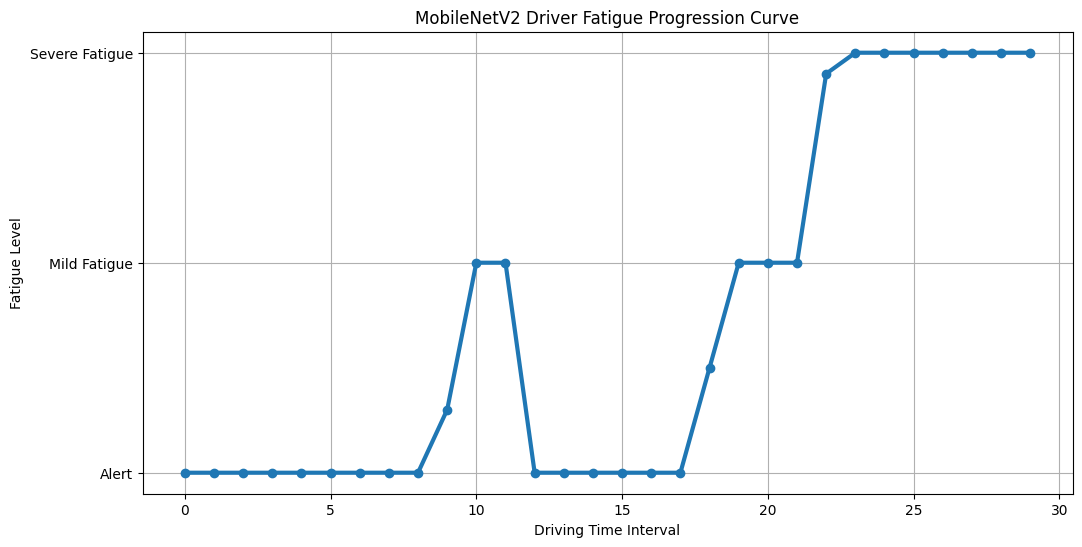

    Time Interval  Fatigue Score           Stage
0               1            0.0           Alert
1               2            0.0           Alert
2               3            0.0           Alert
3               4            0.0           Alert
4               5            0.0           Alert
5               6            0.0           Alert
6               7            0.0           Alert
7               8            0.0           Alert
8               9            0.0           Alert
9              10            0.3           Alert
10             11            1.0    Mild Fatigue
11             12            1.0    Mild Fatigue
12             13            0.0           Alert
13             14            0.0           Alert
14             15            0.0           Alert
15             16            0.0           Alert
16             17            0.0           Alert
17             18            0.0           Alert
18             19            0.5    Mild Fatigue
19             20   

In [52]:
cnn_summary = fatigue_progression_curve(
    cnn_results,
    model_name="Custom CNN"
)

print(cnn_summary)

# for Mobilenet

mobilenet_summary = fatigue_progression_curve(
    mobile_results,
    model_name="MobileNetV2"
)

print(mobilenet_summary)


In [68]:
# ============================================================
# Step 11 : Performance Analysis
# ============================================================

def compare_models(
    cnn_report,
    mobile_report,
    output_dir="outputs/step11_performance_analysis",
    backup_dir=None
):
    """
    Compare the performance of Custom CNN and MobileNetV2.
    Saves:
        • model_comparison.csv
        • model_accuracy_comparison.png
    Optionally copies outputs to Google Drive.
    """

    os.makedirs(output_dir, exist_ok=True)

    # ---------------------------------------------------
    # Create Comparison Table
    # ---------------------------------------------------

    comparison = pd.DataFrame({

        "Metric":[
            "Test Accuracy",
            "Closed Precision",
            "Open Precision",
            "No_yawn Precision",
            "Yawn Precision"
        ],

        "Custom CNN":[
            cnn_report.loc["accuracy", "precision"] * 100,
            cnn_report.loc["Closed", "precision"],
            cnn_report.loc["Open", "precision"],
            cnn_report.loc["no_yawn", "precision"],
            cnn_report.loc["yawn", "precision"]
        ],

        "MobileNetV2":[
            mobile_report.loc["accuracy", "precision"] * 100,
            mobile_report.loc["Closed", "precision"],
            mobile_report.loc["Open", "precision"],
            mobile_report.loc["no_yawn", "precision"],
            mobile_report.loc["yawn", "precision"]
        ]

    })

    comparison.iloc[:,1:] = comparison.iloc[:,1:].round(4)

    print("\nModel Performance Comparison")
    display(comparison)

    # ---------------------------------------------------
    # Save CSV
    # ---------------------------------------------------

    csv_path = os.path.join(
        output_dir,
        "model_comparison.csv"
    )

    comparison.to_csv(csv_path, index=False)

    print(f"\n✅ Comparison saved to: {csv_path}")

    # ---------------------------------------------------
    # Accuracy Visualization
    # ---------------------------------------------------

    accuracy = comparison.loc[
        comparison["Metric"] == "Test Accuracy"
    ]

    models = ["Custom CNN", "MobileNetV2"]

    accuracies = [
        accuracy["Custom CNN"].values[0],
        accuracy["MobileNetV2"].values[0]
    ]

    plt.figure(figsize=(6,5))

    bars = plt.bar(models, accuracies)

    plt.title("Model Accuracy Comparison")

    plt.ylabel("Test Accuracy (%)")

    plt.ylim(0,100)

    for bar in bars:

        height = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 1,
            f"{height:.2f}%",
            ha="center",
            fontsize=10,
            fontweight="bold"
        )

    plt.tight_layout()

    plot_path = os.path.join(
        output_dir,
        "model_accuracy_comparison.png"
    )

    plt.savefig(plot_path, dpi=300)

    plt.show()

    print(f"✅ Accuracy graph saved to: {plot_path}")

    # ---------------------------------------------------
    # Optional Google Drive Backup
    # ---------------------------------------------------

    if backup_dir is not None:

        os.makedirs(backup_dir, exist_ok=True)

        shutil.copy(csv_path, backup_dir)
        shutil.copy(plot_path, backup_dir)

        print(f"✅ Backup copied to: {backup_dir}")

    return comparison



Model Performance Comparison


,Metric,Custom CNN,MobileNetV2
0,Test Accuracy,69.3878,88.0952
1,Closed Precision,0.6897,1.0000
2,Open Precision,0.7833,0.9867
3,No_yawn Precision,0.7018,0.7241
4,Yawn Precision,0.6333,0.8305



✅ Comparison saved to: outputs/step11_performance_analysis/model_comparison.csv


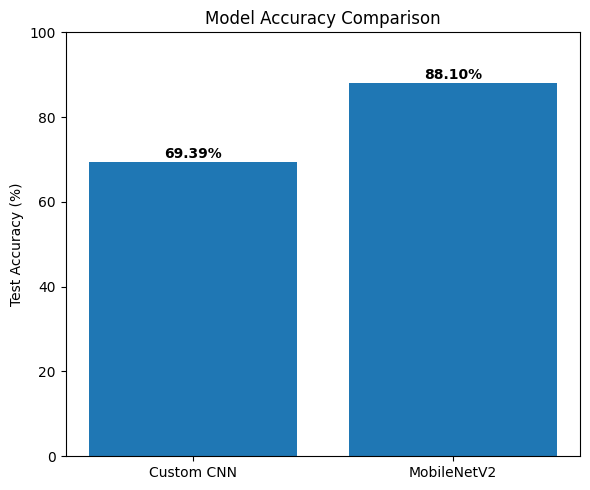

✅ Accuracy graph saved to: outputs/step11_performance_analysis/model_accuracy_comparison.png
✅ Backup copied to: /content/drive/MyDrive/project/outputs/step11_performance_analysis


In [69]:
comparison = compare_models(
    cnn_report,
    mobile_report,
    backup_dir="/content/drive/MyDrive/project/outputs/step11_performance_analysis"
)
